In [3]:
import sys
from pathlib import Path
raiz_projeto = Path().resolve().parent
if str(raiz_projeto) not in sys.path:
    sys.path.append(str(raiz_projeto))

import pandas as pd
from sqlalchemy import create_engine
import matplotlib.pyplot as plt
import seaborn as sns
from src import config
sns.set_theme(style="whitegrid")


engine = create_engine(config.DATABASE_URL)

In [4]:
query = """
    WITH pedido AS (
        SELECT o.order_id,
               c.customer_state AS estado,
               SUM(oi.price)    AS valor
        FROM orders o
        JOIN customers   c  ON c.customer_id = o.customer_id
        JOIN order_items oi ON oi.order_id   = o.order_id
        WHERE o.order_status <> 'canceled'
        GROUP BY o.order_id, c.customer_state
    )
    SELECT estado,
           COUNT(*)   AS pedidos,
           SUM(valor) AS receita,
           AVG(valor) AS ticket_medio,
           PERCENTILE_CONT(0.5) WITHIN GROUP (ORDER BY valor) AS ticket_mediana
    FROM pedido
    GROUP BY estado
    ORDER BY receita DESC
"""
df_uf = pd.read_sql(query, engine)
df_uf

,estado,pedidos,receita,ticket_medio,ticket_mediana
0,SP,41128,5165166.12,125.587583,79.800
1,RJ,12698,1811923.32,142.693599,89.990
2,MG,11497,1573667.19,136.876332,89.900
3,RS,5416,742809.68,137.150975,89.000
4,PR,4982,676883.06,135.865729,84.990
5,SC,3599,518578.28,144.089547,89.900
6,BA,3344,507108.83,151.647377,93.995
7,DF,2120,300886.45,141.927571,87.850
8,GO,1998,287870.46,144.079309,89.990
9,ES,2018,273532.13,135.546150,89.000


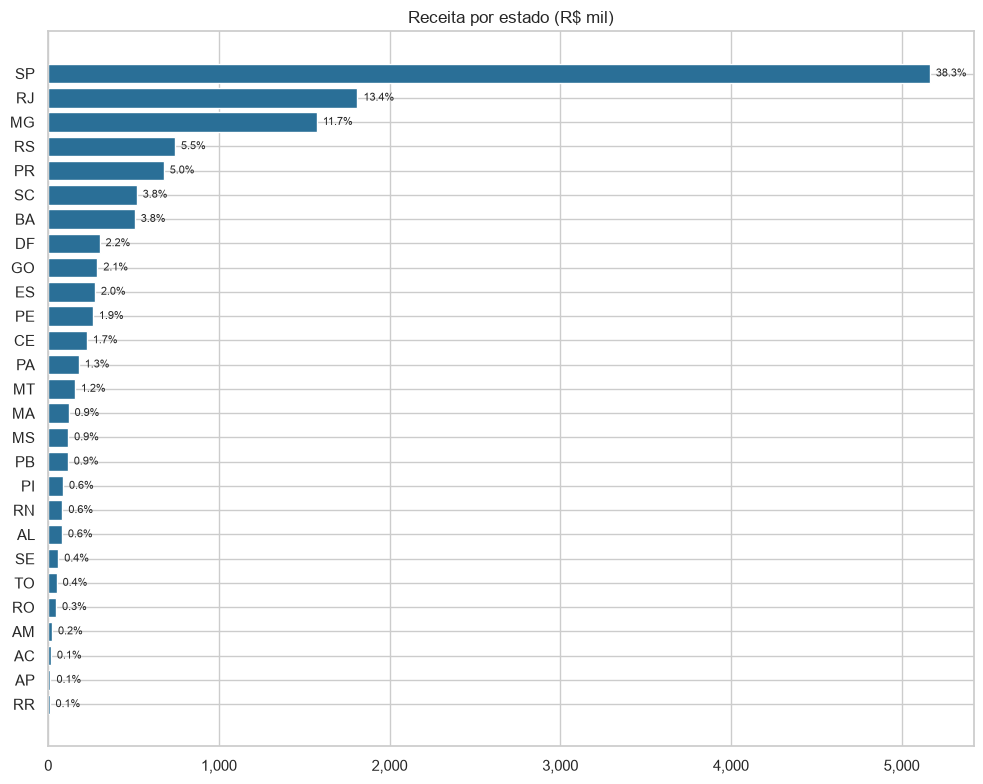

In [5]:
df_uf["participacao"] = df_uf["receita"] / df_uf["receita"].sum()
ordem = df_uf.sort_values("receita", ascending=True)

fig, ax = plt.subplots(figsize=(10, 8))
ax.barh(ordem["estado"], ordem["receita"], color="#2a6f97")
ax.xaxis.set_major_formatter(lambda x, _: f"{x/1000:,.0f}")
ax.set_title("Receita por estado (R$ mil)")

for i, (rec, part) in enumerate(zip(ordem["receita"], ordem["participacao"])):
    ax.text(rec, i, f"  {part:.1%}", va="center", fontsize=8)

plt.tight_layout()
plt.show()